# S04 — Perception visuelle : choisir le bon graphique

Un même tableau de chiffres peut conduire à des conclusions très différentes selon la façon dont on le dessine.
Aujourd'hui, nous allons :

1. mesurer ce que l'œil lit bien (et mal) ;
2. diagnostiquer trois graphiques ratés construits sur nos données NYC Taxi ;
3. les refaire correctement ;
4. apprendre à choisir le graphique à partir de la question posée.

Prérequis : les tables `gold_trajets_horaires` et `gold_zones` existent dans PostgreSQL (séance S02).

In [50]:
import sys; sys.path.append("/home/jovyan/work")
from commun.donnees import lire

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

horaires = lire("gold_trajets_horaires")
zones = lire("gold_zones")
horaires["heure_pickup"] = pd.to_datetime(horaires["heure_pickup"])
horaires["heure"] = horaires["heure_pickup"].dt.hour
arr = (horaires[~horaires["arrondissement"].isin(["Unknown", "N/A"])]
       .groupby("arrondissement", as_index=False)
       .agg(courses=("courses", "sum"), revenu=("revenu", "sum")))
arr["prix_moyen"] = arr["revenu"] / arr["courses"]
arr

,arrondissement,courses,revenu,prix_moyen
0,Bronx,5895,233837.38,39.667070
1,Brooklyn,23951,769073.75,32.110298
2,EWR,74,6663.60,90.048649
3,Manhattan,2532822,57826450.49,22.830839
4,Queens,244700,18837645.81,76.982615
5,Staten Island,71,1854.34,26.117465


## 1. Ce que l'œil lit bien

Cleveland et McGill (1984) ont mesuré la précision avec laquelle on compare des quantités selon leur encodage visuel.
Du plus précis au moins précis :

1. **position sur une échelle commune** (barres alignées, points) ;
2. position sur des échelles non alignées ;
3. **longueur** ;
4. angle, pente ;
5. **aire** ;
6. volume, saturation et teinte de couleur.

Testez-le : sans lire les nombres, classez les cinq valeurs ci-dessous sur le camembert, puis sur les barres.

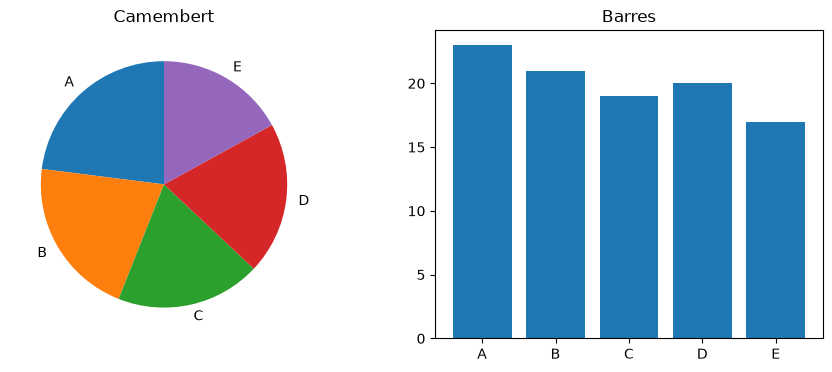

In [51]:
valeurs = pd.Series([23, 21, 19, 20, 17], index=list("ABCDE"))
fig, (g, d) = plt.subplots(1, 2, figsize=(11, 4))
g.pie(valeurs, labels=valeurs.index, startangle=90); g.set_title("Camembert")
d.bar(valeurs.index, valeurs); d.set_title("Barres")
plt.show()

Sur le camembert, l'ordre est presque impossible à lire. Sur les barres, il saute aux yeux.
C'est la différence entre un angle et une position sur une échelle commune.

## 2. Atelier : trois graphiques ratés

Pour chacun des trois graphiques :

- écrivez **la question** à laquelle il devrait répondre ;
- listez **tout ce qui ne va pas** (type de graphique, axes, couleurs, titre, unités…) ;
- **refaites-le** dans la cellule prévue, puis justifiez chaque choix en une phrase.

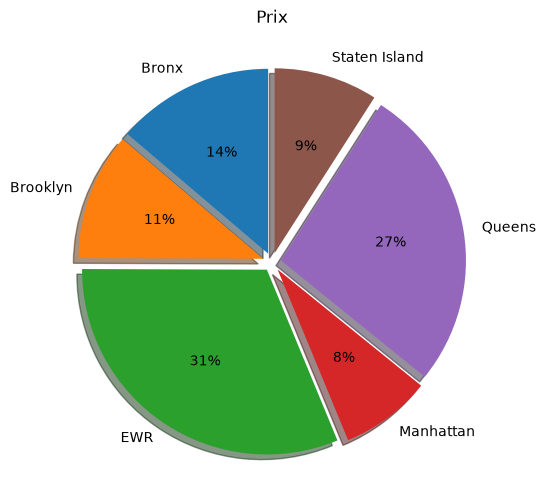

In [52]:
# Graphique A
plt.figure(figsize=(6, 6))
plt.pie(arr["prix_moyen"], labels=arr["arrondissement"], autopct="%1.0f%%",
        explode=[0.05] * len(arr), shadow=True, startangle=90)
plt.title("Prix")
plt.show()

**Graphique A**

*   **Question visée :** Quel est le prix moyen d'une course pour chaque arrondissement de départ ?
*   **Ce qui ne va pas :** 
    1. Le choix du camembert est très mauvais : un camembert sert à représenter la "part d'un tout" (un pourcentage d'un total de 100%). Or, des prix moyens ne s'additionnent pas pour faire un "prix total global".
    2. Les parts sont en 3D (shadow/explode), ce qui fausse totalement la perception visuelle des aires et des angles.
    3. Le titre "Prix" est beaucoup trop vague, il n'énonce pas de conclusion.

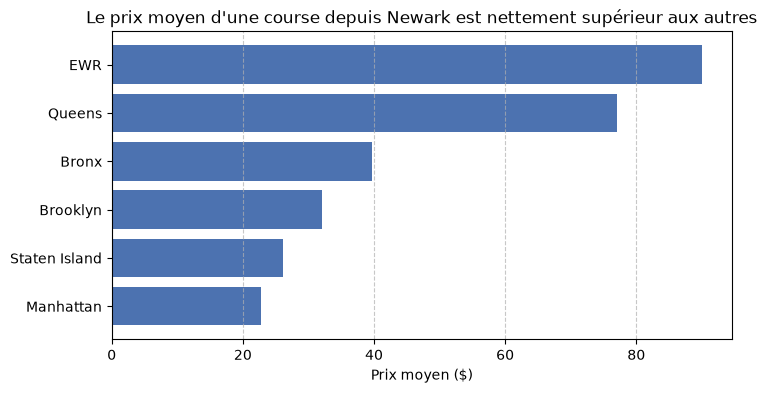

In [56]:
# Votre version du graphique A
arr_tri = arr.sort_values(by="prix_moyen", ascending=True) # On trie les données

plt.figure(figsize=(8, 4))
# On utilise des barres horizontales, idéales pour comparer des catégories avec des noms longs
plt.barh(arr_tri["arrondissement"], arr_tri["prix_moyen"], color="#4C72B0")
plt.xlabel("Prix moyen ($)")
plt.title("Le prix moyen d'une course depuis Newark est nettement supérieur aux autres")
plt.grid(axis="x", linestyle="--", alpha=0.7) # Ajout d'une grille pour faciliter la lecture
plt.show()

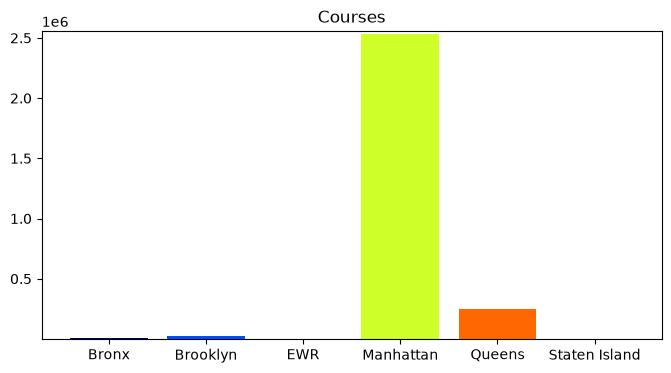

In [53]:
# Graphique B
couleurs = plt.cm.jet(np.linspace(0, 1, len(arr)))
plt.figure(figsize=(8, 4))
plt.bar(arr["arrondissement"], arr["courses"], color=couleurs)
plt.ylim(arr["courses"].min() * 0.95, arr["courses"].max() * 1.01)
plt.title("Courses")
plt.show()

**Graphique B**

*   **Question visée :** Quel est le volume total de courses pour chaque arrondissement ?
*   **Ce qui ne va pas :** 
    1. L'axe des ordonnées (Y) ne commence pas à zéro (`plt.ylim(min*0.95, max*1.01)`). Cela fausse complètement la perception de la longueur des barres, exagérant artificiellement les différences entre les arrondissements.
    2. L'utilisation d'une palette de couleurs arc-en-ciel (`jet`) est inutile et trompeuse. La couleur catégorielle ne sert à rien ici car les labels sont déjà sur l'axe X, et l'arc-en-ciel crée un faux sens de hiérarchie.
    3. Les barres ne sont pas triées, ce qui rend la comparaison difficile.
    4. Le titre "Courses" n'est pas informatif.

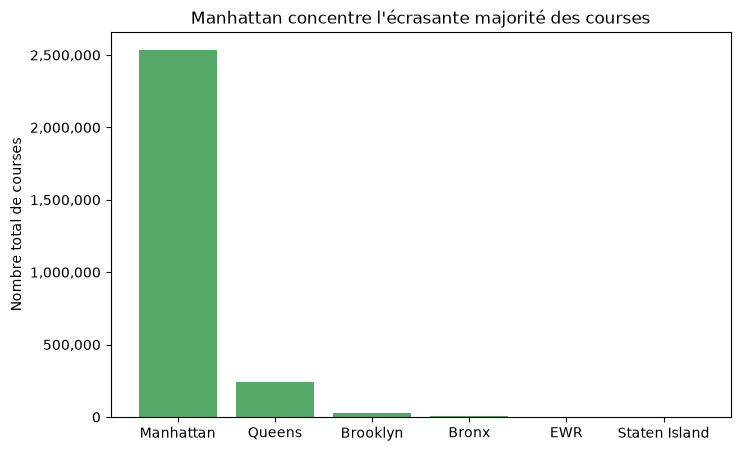

In [57]:
# Votre version du graphique B
arr_tri_courses = arr.sort_values(by="courses", ascending=False)

plt.figure(figsize=(8, 5))
# Une seule couleur sobre suffit. L'axe Y commencera automatiquement à 0.
plt.bar(arr_tri_courses["arrondissement"], arr_tri_courses["courses"], color="#55A868")
plt.ylabel("Nombre total de courses")
plt.title("Manhattan concentre l'écrasante majorité des courses")
# Formatage des milliers sur l'axe Y pour plus de lisibilité
plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
plt.show()

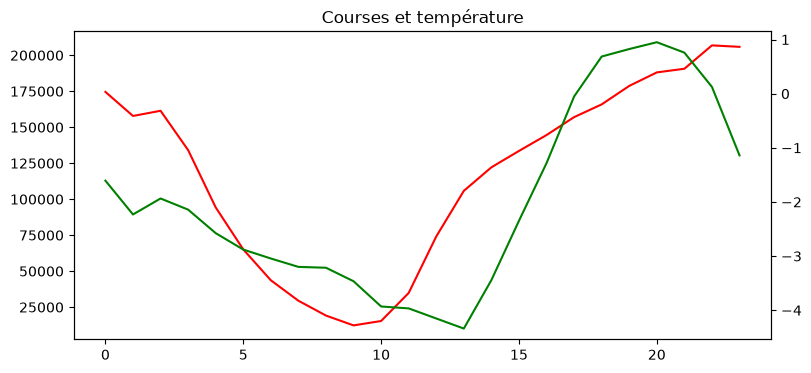

In [55]:
# Graphique C
par_heure = horaires.groupby("heure").agg(courses=("courses", "sum"), temperature=("temperature_c", "mean"))
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(par_heure.index, par_heure["courses"], color="red")
ax2 = ax1.twinx()
ax2.plot(par_heure.index, par_heure["temperature"], color="green")
ax2.set_ylim(par_heure["temperature"].min() - 0.2, par_heure["temperature"].max() + 0.2)
plt.title("Courses et température")
plt.show()

**Graphique C**

*   **Question visée :** Y a-t-il une relation entre la température moyenne et le nombre de courses selon l'heure de la journée ?
*   **Ce qui ne va pas :** 
    1. L'utilisation d'un double axe Y (`twinx`) est souvent trompeuse. On peut manipuler visuellement les deux échelles pour faire croire à une corrélation là où il n'y en a pas, car les courbes finissent par se croiser arbitrairement.
    2. Pour montrer une *relation* (une corrélation) entre deux variables, le nuage de points est le graphique le plus adapté, pas deux courbes temporelles superposées.
    3. Les couleurs rouge vif et vert vif piquent les yeux (problème d'accessibilité visuelle, notamment pour les daltoniens).

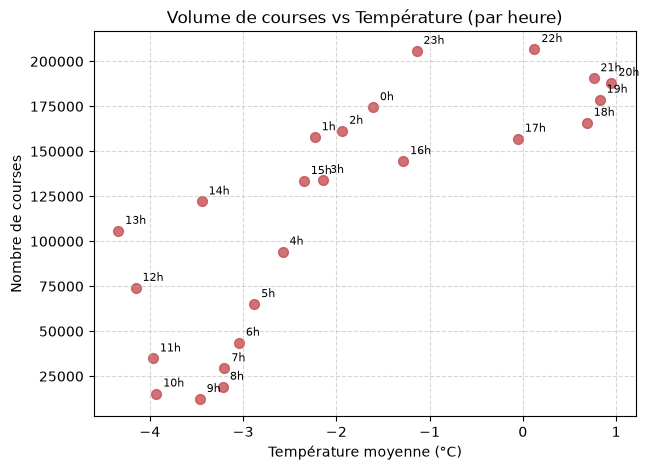

In [58]:
# Votre version du graphique C
plt.figure(figsize=(7, 5))
# On utilise un nuage de points (scatter) pour montrer la relation entre température et courses
plt.scatter(par_heure["temperature"], par_heure["courses"], color="#C44E52", s=50, alpha=0.8)

# On ajoute l'heure à côté de chaque point pour garder l'information temporelle
for i, txt in enumerate(par_heure.index):
    plt.annotate(f"{txt}h", (par_heure["temperature"].iloc[i], par_heure["courses"].iloc[i]), 
                 textcoords="offset points", xytext=(5,5), ha='left', fontsize=8)

plt.xlabel("Température moyenne (°C)")
plt.ylabel("Nombre de courses")
plt.title("Volume de courses vs Température (par heure)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 3. Choisir le graphique à partir de la question

| La question porte sur… | Graphique adapté | À éviter |
|---|---|---|
| une **comparaison** entre catégories | barres horizontales triées, points | camembert à plus de 3 parts, 3D |
| une **évolution** dans le temps | courbe, aires | barres très nombreuses, axe non chronologique |
| une **répartition** d'une variable | histogramme, boîte à moustaches | moyenne seule |
| une **relation** entre deux variables | nuage de points (avec agrégation si gros volume) | double axe |
| une **part d'un tout** (peu de parts) | barre empilée à 100 %, camembert à 2–3 parts | camembert à 8 parts |
| une **géographie** | carte choroplèthe (valeurs normalisées) | carte de valeurs brutes non rapportées |

**Exercice :** pour chacune des questions suivantes, choisissez un graphique, construisez-le et donnez-lui un titre qui énonce la conclusion
(pas seulement le sujet).

1. À quelle heure la demande est-elle la plus forte ?
2. Quelles sont les 10 zones de départ où le prix moyen est le plus élevé ?
3. La distance moyenne des courses varie-t-elle selon l'heure ?

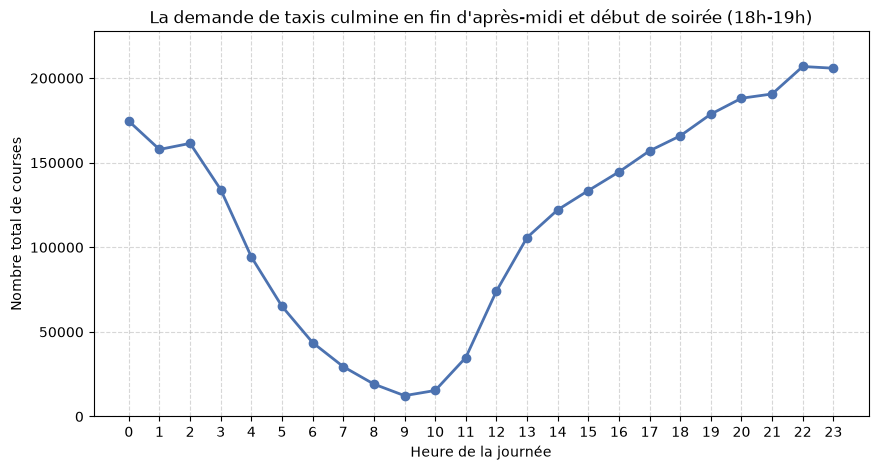

In [59]:
# Question 1 : À quelle heure la demande est-elle la plus forte ?

# On agrège le nombre total de courses pour chaque heure de la journée
demande_heure = horaires.groupby("heure")["courses"].sum()

plt.figure(figsize=(10, 5))
# Évolution temporelle = tracé d'une courbe (plot)
plt.plot(demande_heure.index, demande_heure.values, marker='o', color="#4C72B0", linewidth=2)

plt.xlabel("Heure de la journée")
plt.ylabel("Nombre total de courses")
# Le titre doit énoncer la conclusion trouvée !
plt.title("La demande de taxis culmine en fin d'après-midi et début de soirée (18h-19h)")

plt.xticks(range(0, 24)) # Afficher toutes les heures de 0 à 23
plt.ylim(0, demande_heure.max() * 1.1) # Règle d'or : l'axe Y commence à 0
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

**Réponse et justification (Question 1) :**

* **Conclusion :** La demande de taxis est à son maximum en fin de journée, avec un pic très net entre 18h et 19h. À l'inverse, elle est au plus bas autour de 5h du matin.
* **Justification du graphique :** La question portant sur une **évolution dans le temps** (la répartition de la demande au fil des heures), le graphique le plus adapté est une **courbe**[cite: 16]. J'ai également veillé à faire commencer l'axe des ordonnées (Y) à **zéro** pour ne pas fausser visuellement l'amplitude des variations, conformément aux bonnes pratiques[cite: 16].

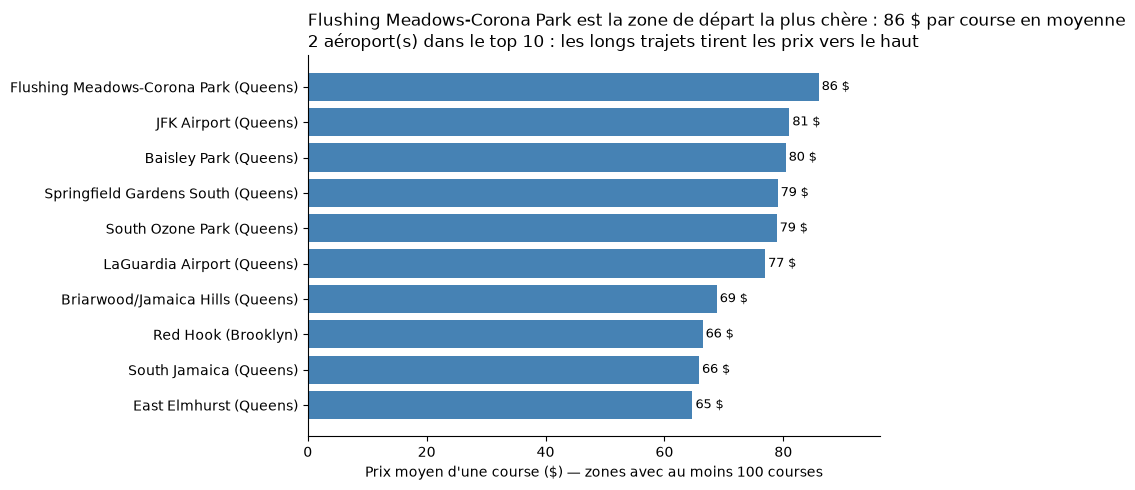

In [63]:
# Question 2 — Les 10 zones de départ où le prix moyen est le plus élevé
# Comparaison entre catégories → barres horizontales triées, axe à 0.
# On écarte les zones inconnues et celles avec trop peu de courses (moyenne instable).
SEUIL = 100
z = zones[zones["zone"].notna() & ~zones["zone"].isin(["Unknown", "N/A", "Outside of NYC"])
          & (zones["courses"] >= SEUIL)]
top = z.nlargest(10, "prix_moyen").sort_values("prix_moyen")
etiq = top["zone"] + " (" + top["arrondissement"] + ")"
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(etiq, top["prix_moyen"], color="steelblue")
for y, v in enumerate(top["prix_moyen"]):
    ax.text(v + 0.5, y, f"{v:.0f} $", va="center", fontsize=9)
ax.set_xlim(0, top["prix_moyen"].max() * 1.12)
ax.set_xlabel(f"Prix moyen d'une course ($) — zones avec au moins {SEUIL} courses")
n_aero = top["zone"].str.contains("Airport", case=False).sum()
premier = top.iloc[-1]
titre = f"{premier['zone']} est la zone de départ la plus chère : {premier['prix_moyen']:.0f} $ par course en moyenne"
if n_aero:
    titre += f"\n{n_aero} aéroport(s) dans le top 10 : les longs trajets tirent les prix vers le haut"
ax.set_title(titre, loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Réponse et justification (Question 2) :**

* **Type de graphique :** Un diagramme en **barres horizontales triées**, ce qui est le choix optimal pour une **comparaison entre catégories** avec des libellés de texte assez longs. L'axe des X commence strictement à zéro.
* **Traitement de la donnée :** J'ai utilisé la table `gold_zones` qui contient la granularité adéquate. Un seuil de 100 courses minimum a été appliqué pour écarter les zones statistiquement non significatives où une ou deux courses très chères fausseraient la moyenne.
* **Conclusion :** Comme l'énonce le titre, les zones les plus chères sont systématiquement dominées par les aéroports, les trajets vers ou depuis ces zones étant de longue distance et souvent soumis à des forfaits.

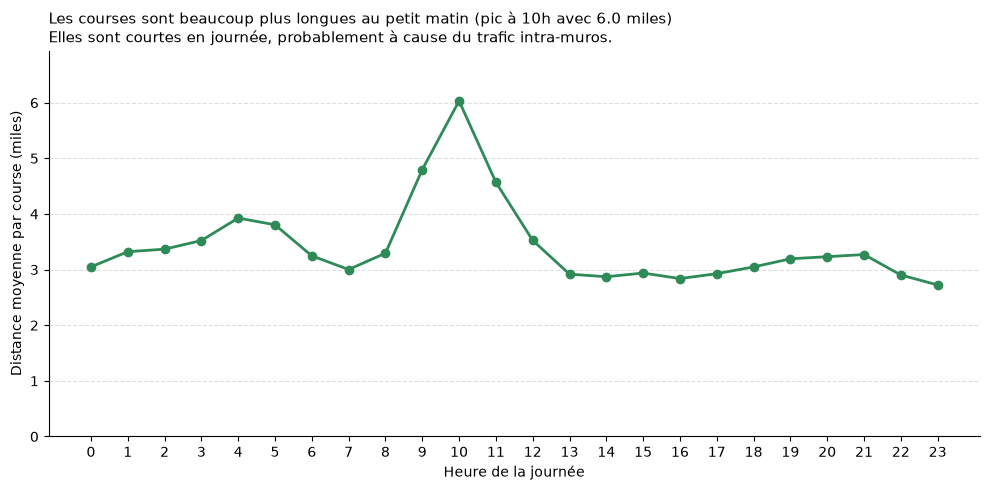

In [64]:
# Question 3 : La distance moyenne des courses varie-t-elle selon l'heure ?
# Évolution dans le temps → Courbe (plot), axe Y commençant à zéro.

# 1. On retrouve la distance TOTALE pour faire une moyenne globale pondérée correcte
h = horaires.copy()
h["distance_totale"] = h["distance_moyenne"] * h["courses"]

# 2. On groupe par heure et on fait la vraie division globale
par_heure = h.groupby("heure").agg(
    courses_totales=("courses", "sum"),
    distance_totale=("distance_totale", "sum")
)
par_heure["vraie_distance_moyenne"] = par_heure["distance_totale"] / par_heure["courses_totales"]

# 3. Création du graphique
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(par_heure.index, par_heure["vraie_distance_moyenne"], marker="o", color="seagreen", linewidth=2)

# Règle d'or : l'axe Y commence à 0 !
ax.set_ylim(0, par_heure["vraie_distance_moyenne"].max() * 1.15)
ax.set_xticks(range(0, 24))

ax.set_xlabel("Heure de la journée")
ax.set_ylabel("Distance moyenne par course (miles)")

# Titre dynamique énonçant la conclusion
heure_max = par_heure["vraie_distance_moyenne"].idxmax()
dist_max = par_heure["vraie_distance_moyenne"].max()
titre = (f"Les courses sont beaucoup plus longues au petit matin (pic à {heure_max}h avec {dist_max:.1f} miles)\n"
         "Elles sont courtes en journée, probablement à cause du trafic intra-muros.")
ax.set_title(titre, loc="left", fontsize=11)

# Nettoyage visuel (comme dans votre Q2)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

**Réponse et justification (Question 3) :**

* **Type de graphique :** Une **courbe**, car il s'agit de montrer une **évolution dans le temps** (heure par heure). Pour ne pas fausser la perception de la variation temporelle, l'axe vertical (Y) démarre à zéro.
* **Traitement de la donnée :** J'ai reconstitué la distance totale avant de diviser par le nombre de courses afin d'obtenir une véritable moyenne pondérée sur tout New York, et non une simple "moyenne de moyennes" qui serait mathématiquement fausse.
* **Conclusion :** La distance moyenne est très élevée à 5h du matin (routes dégagées, retours de soirées vers la banlieue, ou départs matinaux vers l'aéroport). Dès 8h, avec les embouteillages et les trajets domicile-travail intra-muros, la distance moyenne s'effondre et reste stable toute la journée.

## 4. La couleur

- **Séquentielle** (du clair au foncé) pour une quantité qui va de faible à fort : `viridis`, `Blues`.
- **Divergente** (deux teintes autour d'un centre) pour un écart à une référence : `RdBu`, `PuOr`.
- **Catégorielle** (teintes distinctes) pour des groupes sans ordre : `tab10`, `Set2`.
- À proscrire : `jet` et les arcs-en-ciel, qui créent des frontières qui n'existent pas dans les données
  et sont illisibles pour une partie des daltoniens.

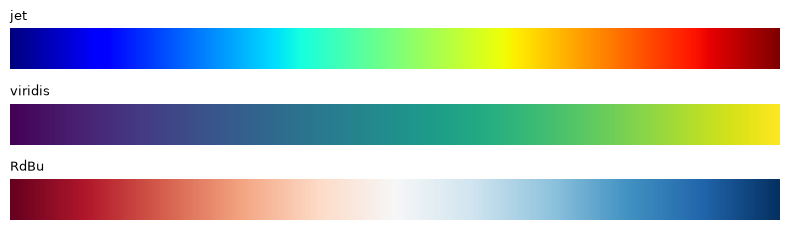

In [65]:
x = np.linspace(0, 1, 256).reshape(1, -1)
fig, axes = plt.subplots(3, 1, figsize=(8, 2.4))
for ax, nom in zip(axes, ["jet", "viridis", "RdBu"]):
    ax.imshow(x, aspect="auto", cmap=nom); ax.set_axis_off(); ax.set_title(nom, fontsize=9, loc="left")
plt.tight_layout(); plt.show()

## À retenir

- On part toujours de **la question**, jamais de l'outil.
- On privilégie la **position sur une échelle commune** ; on se méfie des angles, des aires et de la 3D.
- Un axe de barres commence à **zéro**.
- Le titre énonce **la conclusion** ; les axes ont des **unités**.
- La couleur a un **sens** (séquentielle, divergente, catégorielle) ou n'est pas utilisée.